In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [3]:
iris=load_iris()
data=pd.DataFrame(iris.data,columns=iris.feature_names)
data['target']=iris.target
data.head()



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
df=data.copy()

In [5]:
print("shape:",df.shape)
print("\n")
print(iris.feature_names)
print("\n")
print(iris.target_names)
print("\n")
df.info()
print("\n")
print(df.isnull().sum())


shape: (150, 5)


['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


['setosa' 'versicolor' 'virginica']


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


Exploratory Data Analysis-EDA

In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [7]:
print(df['target'].value_counts())

target
0    50
1    50
2    50
Name: count, dtype: int64


## visualization-countplot,pairplot,heatmap

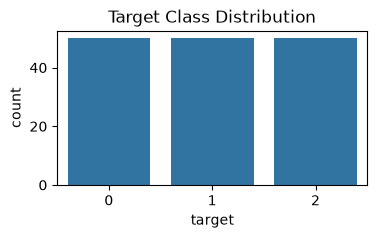

In [8]:
plt.figure(figsize=(4,2))
sns.countplot(x='target', data=df)
plt.title("Target Class Distribution")
plt.show()

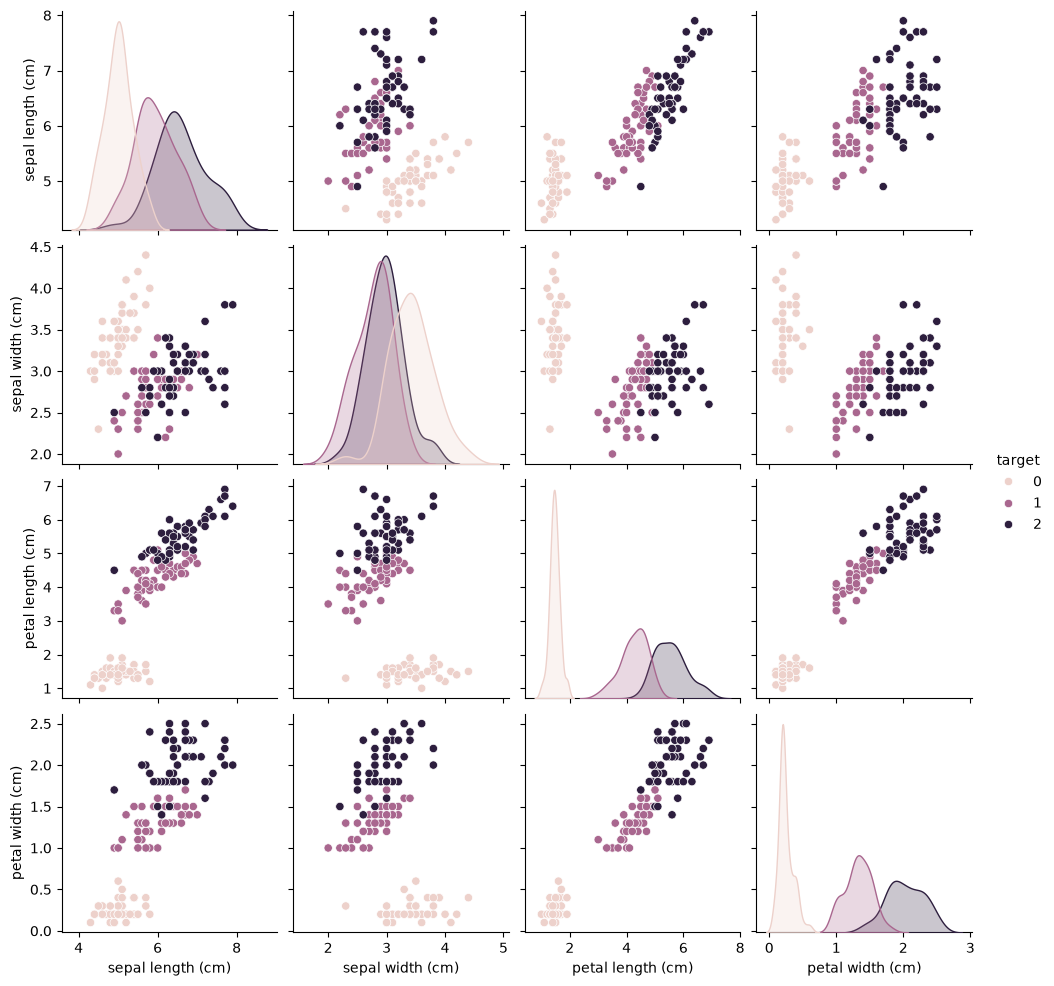

In [9]:
sns.pairplot(df, hue='target')
plt.show()

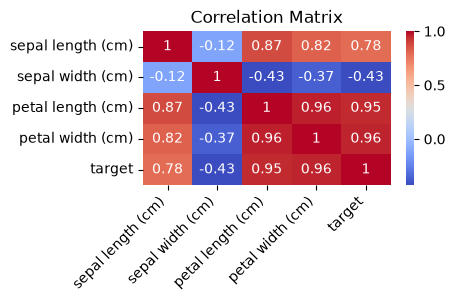

In [10]:
plt.figure(figsize=(4,2))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title("Correlation Matrix")
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.show()

## Split Features and Target

In [11]:
X = df.drop('target', axis=1)
y = df['target']

In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_train.shape,X_test.shape,y_train.shape,y_test.shape


((120, 4), (30, 4), (120,), (30,))

Standard Scaler

In [13]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [15]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC()
}

In [16]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    print(name)
    print("Predictions:", y_pred)
    print()

Logistic Regression
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Decision Tree
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Random Forest
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

SVM
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]



In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [18]:
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    print("Model:", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("-" * 50)

Model: Logistic Regression
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
--------------------------------------------------
Model: Decision Tree
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.9

In [19]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy
0,Logistic Regression,0.933333
1,Decision Tree,0.933333
2,Random Forest,0.933333
3,SVM,0.966667


In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    print("\nModel:", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("-" * 50)


Model: Logistic Regression
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
--------------------------------------------------

Model: Decision Tree
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.

In [21]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy
0,Logistic Regression,0.933333
1,Decision Tree,0.933333
2,Random Forest,0.933333
3,SVM,0.966667


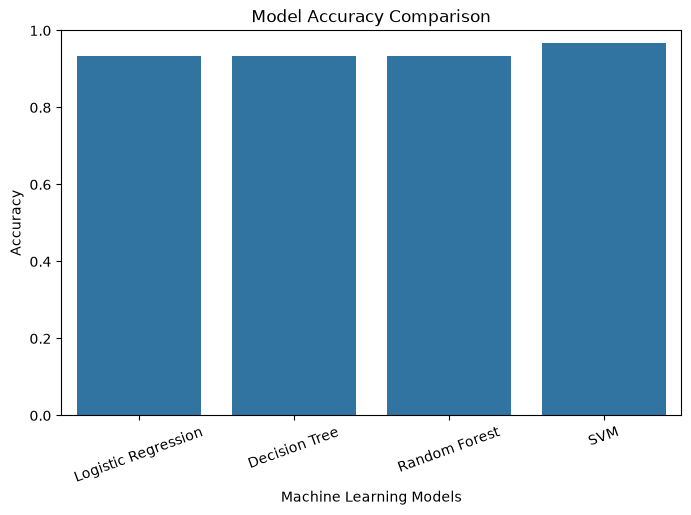

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.show()

In [23]:
best_model = models['SVM']

y_pred_svm = best_model.predict(X_test_scaled)

print("SVM Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=iris.target_names
))

SVM Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



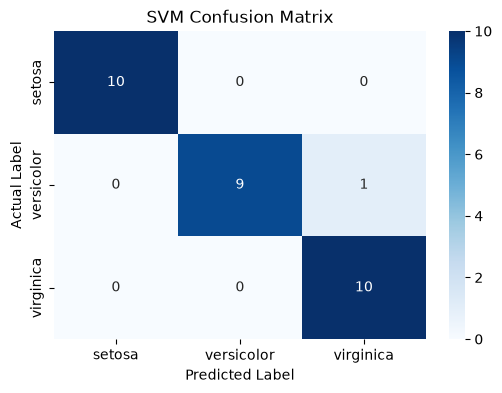

In [24]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

c:\Users\keert\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
c:\Users\keert\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


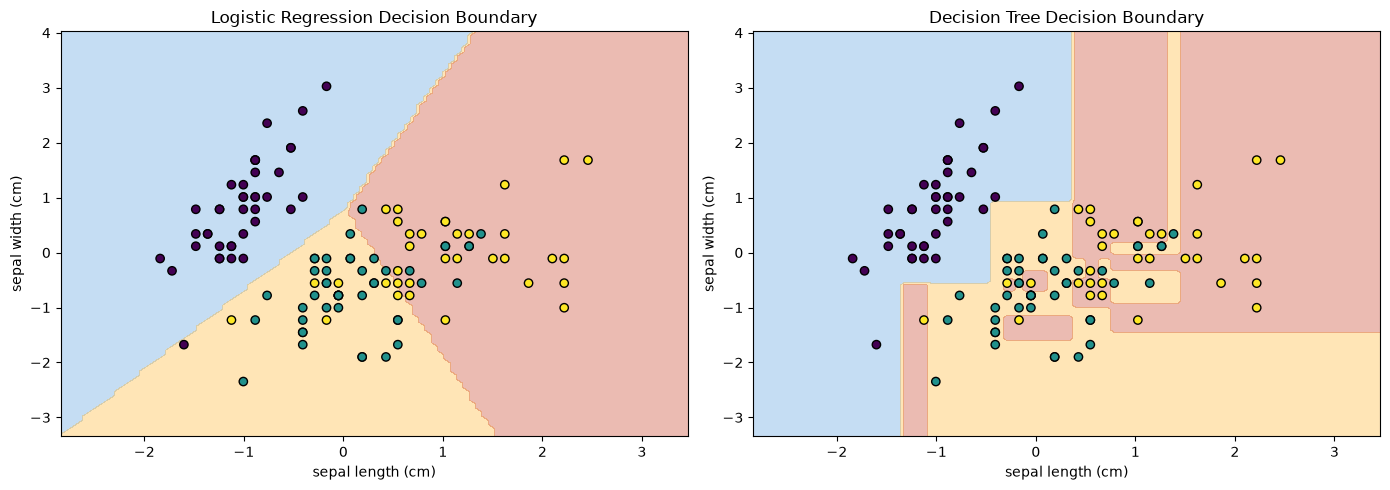

In [25]:
from sklearn.inspection import DecisionBoundaryDisplay

X_train_2d = X_train_scaled[:, :2]

visual_models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, visual_models.items()):

    model.fit(X_train_2d, y_train)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method='predict',
        ax=ax,
        alpha=0.3,
        cmap='viridis'
    )

    ax.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=y_train,
        edgecolors='black',
        cmap='viridis'
    )

    ax.set_title(name + ' Decision Boundary')
    ax.set_xlabel(iris.feature_names[0])
    ax.set_ylabel(iris.feature_names[1])

plt.tight_layout()
plt.show()

In [26]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC()
}

In [27]:
models

{'Logistic Regression': LogisticRegression(),
 'Decision Tree': DecisionTreeClassifier(random_state=42),
 'Random Forest': RandomForestClassifier(random_state=42),
 'SVM': SVC()}

## Conclusion

In this project, a Multi-Class Classification Pipeline was developed using the Iris dataset and Scikit-Learn.

Exploratory Data Analysis (EDA) was performed using Pandas, Seaborn, and Matplotlib to understand the dataset and identify relationships between features.

The dataset was divided into training and testing sets using an 80:20 ratio. StandardScaler was applied to standardize the numerical features before model training.

Four supervised machine learning algorithms were implemented and evaluated:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Support Vector Machine (SVM)

Model performance was evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrices.

Among the four models, Support Vector Machine (SVM) achieved the highest accuracy of **96.67%**, followed by Logistic Regression, Decision Tree, and Random Forest, each achieving **93.33%** accuracy.

This project provided practical experience in data preprocessing, exploratory data analysis, feature scaling, multi-class classification, model comparison, and performance evaluation.

Overall, the project demonstrates the application of supervised machine learning techniques to solve a multi-class classification problem.